# Lab 05 — Unsupervised learning II: anomaly detection and limited labels

*Ranking card fraud without labels, and getting the most from a small labeling budget*

**Goal.** Rank 85,000 card transactions for review with an anomaly detector that never sees a fraud label, judge the ranking with metrics that respect a 0.17% base rate, then stretch a small labeling budget for a bank's customer-support messages with self-training and active learning, checking each against a labels-only baseline.

**Data.** `all_datasets/unsupervised/creditcard_fraud_ulb/creditcard_fraud_ulb.zip`, `all_datasets/advanced/banking77/banking77.csv`

**Reading.** Chapters 23 and 25: anomaly detection, semi-supervised and active learning.

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab05_anomaly_limited_labels/lab05_anomaly_limited_labels_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab05_anomaly_limited_labels/lab05_anomaly_limited_labels_worked.py`.

**Evidence.** `results/lab05/` — `metrics.csv`, the top-ranked transactions, the active-learning curve and two figures

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Rank card fraud with an Isolation Forest and judge the ranking | 2–4 |
| B | Self-train from 1,000 labels; compare two ways of buying labels | 5–9 |
| Finish | Save the evidence; then size a review budget and read the messages the learner finds hardest | 10–12 |
| After | Your-turn tasks, expected findings, troubleshooting and the two checklists (on the lab sheet) | — |

## Setup

Imports and paths. `start_lab()`, from `all_experiments/course_setup.py`, finds the course folder by looking upward for `all_datasets/`; figures and tables go to `results/lab05/`.

### Question 1 — Setup

**Read the code.**

- The setup has the same three steps as before.
- `IsolationForest` is a detector that needs no labels, `TfidfVectorizer` turns messages into weighted word columns, and `SelfTrainingClassifier` wraps a classifier so that it can learn from its own confident guesses.

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab

# 2. The libraries this lab uses.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest                       # a detector that needs no labels
from sklearn.feature_extraction.text import TfidfVectorizer        # messages -> word weights
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.semi_supervised import SelfTrainingClassifier         # learns from its own confident guesses

# 3. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab05")

course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab05/ and models/


## Part A — Ranking fraud without labels

**Goal.** Rank card transactions with a detector that never sees a fraud label, and judge the ranking at a 0.17% base rate.

*Questions 2–4 · Data: ULB card transactions*

### Question 2 — Fit an Isolation Forest without labels

The ULB card-fraud table holds 284,807 transactions made by European cardholders over two days in September 2013, 492 of them fraud. To protect the cardholders, the bank released its columns as 28 anonymous principal components, `V1` to `V28`, plus the time and the amount. An Isolation Forest is fitted on the training rows *without* the fraud column; it learns what ordinary looks like, and scores how easily each transaction can be isolated.

**Read the code.**

- `cards["Time"].max() / 3600` turns seconds into hours.
- `[f"V{i}" for i in range(1, 29)]` builds the 28 column names from `V1` to `V28`. `.copy()` makes the selection an independent table, so adding `log_amount` to it is safe.
- `train_test_split(..., stratify=y)` uses the labels for one purpose: to give both sides the same fraud rate.
- `forest.fit(X_train)` receives no labels. An Isolation Forest builds 300 random trees and measures how few splits it takes to cut each transaction off from the rest: unusual ones are cut off quickly.
- `decision_function` is high for ordinary rows, so the minus sign turns it into an anomaly score: higher means more unusual.

In [2]:
cards = pd.read_csv(DATA / "unsupervised/creditcard_fraud_ulb/creditcard_fraud_ulb.zip")
hours = cards["Time"].max() / 3600                                 # Time is in seconds
print("transactions:", len(cards), " over", round(hours), "hours;", int(cards["Class"].sum()), "frauds")

# V1-V28 are anonymized principal components; the amount gets a log for its long tail.
X = cards[[f"V{i}" for i in range(1, 29)]].copy()
X["log_amount"] = np.log1p(cards["Amount"])
y = cards["Class"]

# The labels are used only to split fairly (the same fraud rate on both sides) and, later, to score.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

forest = IsolationForest(n_estimators=300, random_state=42, n_jobs=-1)
forest.fit(X_train)                                   # no labels passed
anomaly_score = -forest.decision_function(X_test)     # higher = more unusual

transactions: 284807  over 48 hours; 492 frauds


### Question 3 — Score the ranking

Accuracy is useless at a 0.17% base rate, so the ranking is judged three ways: ROC AUC, average precision (which guessing scores at the prevalence), and how many frauds a team would find in its first 100 reviews.

**Read the code.**

- `y_test.mean()` is the fraud rate, which is also the average precision that a random ranking would earn.
- `roc_auc_score` and `average_precision_score` need only a score that ranks. The detector never has to answer yes or no.
- `ranked` puts the labels, the scores and the amounts in one table. `cards.loc[X_test.index, "Amount"]` fetches the amounts of the test transactions by their row labels.
- `sort_values("anomaly_score", ascending=False)` puts the most unusual first, so `ranked.head(review_budget)` is the list a reviewer would work through.

In [3]:
prevalence = y_test.mean()                            # the fraud rate: what random guessing would achieve
ap = average_precision_score(y_test, anomaly_score)
print("test transactions:", len(y_test), " frauds:", int(y_test.sum()),
      " prevalence:", round(prevalence, 5))
print("ROC AUC:", round(roc_auc_score(y_test, anomaly_score), 3))
print("average precision:", round(ap, 3), " (", round(ap / prevalence), "x prevalence)")

# The review list: every test transaction, most unusual first.
ranked = pd.DataFrame({
    "fraud_label": y_test.to_numpy(),
    "anomaly_score": anomaly_score,
    "amount": cards.loc[X_test.index, "Amount"].to_numpy(),
}).sort_values("anomaly_score", ascending=False)

review_budget = 100
found = int(ranked.head(review_budget)["fraud_label"].sum())
print(f"frauds in the top {review_budget} alerts: {found}")
print(ranked.head(10).round(3).to_string(index=False))

test transactions: 85443  frauds: 148  prevalence: 0.00173
ROC AUC: 0.95
average precision: 0.219  ( 126 x prevalence)
frauds in the top 100 alerts: 39
 fraud_label  anomaly_score  amount
           0          0.251 4861.64
           0          0.250 1676.60
           1          0.247    2.28
           1          0.242    1.00
           0          0.242 5964.95
           1          0.240    1.00
           1          0.235    1.00
           1          0.235    1.00
           1          0.234    1.00
           1          0.231  364.19


### Question 4 — Plot the scores and precision at k

The score distributions for genuine and fraud transactions, and the fraud rate among the top $k$ alerts as $k$ grows.

**Read the code.**

- `hits[:k].mean()` is the precision at `k`: the share of frauds among the `k` most unusual transactions. The list comprehension computes it for every `k` from 10 to 2,000.
- `anomaly_score[~is_fraud]` and `anomaly_score[is_fraud]` separate the two groups for the histograms. `density=True` scales each histogram to an area of 1, so a few frauds can be compared with tens of thousands of genuine payments.
- `axhline(prevalence, ...)` draws the fraud rate, the level that a random list would reach.

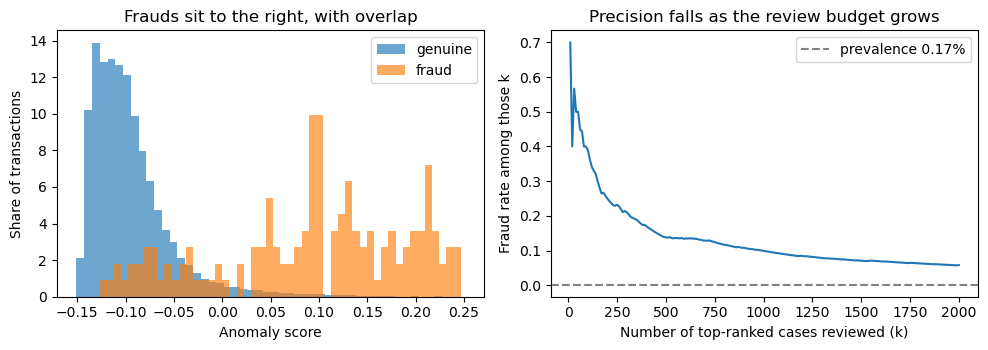

In [4]:
# Precision at k: the fraud rate among the k most unusual transactions, for k = 10, 20, ..., 2000.
hits = ranked["fraud_label"].to_numpy()
k_values = np.arange(10, 2001, 10)
precision_at_k = [hits[:k].mean() for k in k_values]
is_fraud = y_test.to_numpy() == 1

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(anomaly_score[~is_fraud], bins=50, alpha=0.65, density=True, label="genuine")
axes[0].hist(anomaly_score[is_fraud], bins=50, alpha=0.65, density=True, label="fraud")
axes[0].set_xlabel("Anomaly score")
axes[0].set_ylabel("Share of transactions")
axes[0].set_title("Frauds sit to the right, with overlap")
axes[0].legend()
axes[1].plot(k_values, precision_at_k)
axes[1].axhline(prevalence, linestyle="--", color="grey", label=f"prevalence {prevalence:.2%}")
axes[1].set_xlabel("Number of top-ranked cases reviewed (k)")
axes[1].set_ylabel("Fraud rate among those k")
axes[1].set_title("Precision falls as the review budget grows")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS / "precision_falls_as_the_review_budget_grows.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** 284,807 transactions over 48 hours, with 148 frauds among the 85,443 test transactions, a prevalence of 0.17%. Without ever seeing a label, the Isolation Forest ranks them with a ROC AUC of 0.950 and an average precision of 0.219, 126 times the base rate; 39 of its first 100 alerts are fraud. The top of the list is telling: most of its first ten alerts are frauds for exactly \$1.00, the signature of card testing, where a thief checks a stolen card with a tiny purchase. The precision curve falls as the review budget grows, from 50% in the first 50 alerts towards the base rate, which is why a fraud team plans by budget, not by ROC AUC.

**Checkpoint: before you move on**

- ROC AUC 0.950, but average precision only 0.219.
- The top 100 alerts hold 39 of the 148 test frauds.

## Part B — Learning from few labels

**Goal.** Stretch 1,000 labels with self-training, then compare two ways of buying more labels.

*Questions 5–9 · Data: Banking77 customer-support messages*

### Question 5 — Split the messages three ways

Banking77 holds 13,083 messages that customers typed to a bank's support chat, each labeled by hand with one of 77 intents, such as `card_arrival` or `exchange_rate`. A support team that wants to route messages automatically must pay someone to label them, so this part pretends most labels are unknown: a pool of 8,003 messages to learn from, 2,000 for validation, and the official 3,080 test messages, opened once. Turning text into numbers needs only the words, so the TF-IDF vocabulary of single words and word pairs is learned from the pool without any labels.

**Read the code.**

- `messages.drop_duplicates("label").sort_values("label")["intent"].tolist()` keeps one row per label, in label order, and reads off the intent names. The result is a list in which position 0 is the name of label 0.
- The file carries its own `split` column. `train_part.sample(2000, random_state=42)` sets validation messages aside, and `train_part.drop(val.index)` leaves the pool.
- `TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)` builds columns for single words and for pairs of words, ignores those found in fewer than two messages, and dampens repeated words with a logarithm.
- `.fit(pool["text"])` learns the vocabulary from the pool. `transform` then turns each set of messages into a sparse matrix with one column per word or pair.
- `make_model()` returns a fresh classifier each time, so every method in Part B uses the same one.

In [5]:
messages = pd.read_csv(DATA / "advanced/banking77/banking77.csv")
intents = messages.drop_duplicates("label").sort_values("label")["intent"].tolist()      # label 0 to 76

# Three sets: a pool whose labels stay hidden until bought, a validation set, and the official test set.
train_part = messages[messages["split"] == "train"]
test = messages[messages["split"] == "test"]
val = train_part.sample(2000, random_state=42)
pool = train_part.drop(val.index)
print("pool:", len(pool), " validation:", len(val), " test:", len(test), " intents:", len(intents))
print(pool[["text", "intent"]].head(3).to_string(index=False))

# The vocabulary (single words and word pairs) is learned from the pool's text, which needs no labels.
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(pool["text"])
X_pool = vectorizer.transform(pool["text"])
X_val = vectorizer.transform(val["text"])
X_msg_test = vectorizer.transform(test["text"])
y_pool = pool["label"].to_numpy()
y_val = val["label"].to_numpy()
y_msg_test = test["label"].to_numpy()
print("vocabulary:", len(vectorizer.vocabulary_), "words and word pairs")

def make_model():
    """The one classifier used throughout Part B, so only the labels differ between methods."""
    return LogisticRegression(max_iter=2000, C=10)

pool: 8003  validation: 2000  test: 3080  intents: 77
                                                        text       intent
What can I do if my card still hasn't arrived after 2 weeks? card_arrival
  I have been waiting over a week. Is the card still coming? card_arrival
      How do I know if I will get my card, or if it is lost? card_arrival
vocabulary: 8834 words and word pairs


### Question 6 — Self-train from 1,000 labels

Keep the labels of 1,000 pool messages, an eighth of the pool and about 13 per intent, and hide the rest. The baseline uses only those 1,000. Self-training then adopts its own confident predictions (probability at least 0.8) as pseudo-labels, refits, and repeats.

**Read the code.**

- `np.random.default_rng(42)` is a seeded random generator, and `rng.choice(len(y_pool), 1000, replace=False)` draws 1,000 different row positions.
- `np.full(len(y_pool), -1)` starts with every label hidden: -1 is the code for "unlabeled". The next line reveals the 1,000 labels that were drawn.
- `SelfTrainingClassifier(make_model(), threshold=0.80)` fits the model on the labeled rows, predicts the rest, adopts as a label every prediction it is at least 80% sure of, and repeats for up to ten rounds.
- `semi.labeled_iter_ > 0` marks the rows that the model labeled itself (the original labels have round 0), and `semi.transduction_` holds the labels it ended with. Comparing them with the hidden truth shows how many adopted labels were right.
- The last model uses every label of the pool: the ceiling against which the other two are measured.

In [6]:
# 1. The baseline: a model trained on 1,000 randomly chosen labeled messages, an eighth of the pool.
rng = np.random.default_rng(42)
labeled = rng.choice(len(y_pool), 1000, replace=False)
labels_only = make_model().fit(X_pool[labeled], y_pool[labeled])
print("labels only (1,000 messages): validation accuracy",
      round(accuracy_score(y_val, labels_only.predict(X_val)), 3))

# 2. Self-training: the same 1,000 labels, plus its own guesses on the rest when it is at least 80% sure.
y_partial = np.full(len(y_pool), -1)                                    # -1 means unlabeled
y_partial[labeled] = y_pool[labeled]
semi = SelfTrainingClassifier(make_model(), threshold=0.80).fit(X_pool, y_partial)
pseudo = semi.labeled_iter_ > 0                                         # rows it labeled itself
adopted = int(pseudo.sum())
right = np.mean(semi.transduction_[pseudo] == y_pool[pseudo])
print(f"self-training adopted {adopted} pseudo-labels, {right:.1%} of them right")
print("self-training: validation accuracy", round(accuracy_score(y_val, semi.predict(X_val)), 3))

# 3. The ceiling: every one of the pool's labels.
ceiling = make_model().fit(X_pool, y_pool)
print(f"all {len(y_pool):,} labels (the ceiling):",
      round(accuracy_score(y_val, ceiling.predict(X_val)), 3))

labels only (1,000 messages): validation accuracy 0.638


self-training adopted 486 pseudo-labels, 98.8% of them right
self-training: validation accuracy 0.632


all 8,003 labels (the ceiling): 0.882


### Question 7 — Simulate active learning

Active learning chooses which labels to buy. Both policies start from the same 154 labeled messages, two per intent, and buy 100 more per round for ten rounds. Uncertainty sampling buys the messages whose two most likely intents are closest; random querying buys any 100.

**Read the code.**

- `np.where(y_pool == c)[0]` lists the rows of intent `c`, and `rng.choice(..., 2, replace=False)` draws two of them. `np.concatenate` joins the draws of all 77 intents into the 154 starting rows.
- `active_set` and `random_set` are plain lists of row positions that grow by 100 in every round.
- `np.setdiff1d(np.arange(len(y_pool)), active_set)` is every row that is not yet labeled.
- `np.sort(active.predict_proba(...), axis=1)` sorts each message's 77 probabilities, so the last two columns hold its two most likely intents. Their difference is the margin, and a small margin means the model cannot decide.
- `np.argsort(margin)[:query_batch]` gives the positions of the 100 smallest margins, and those messages join the labeled set.
- `break` leaves the loop after the last scoring round, before buying labels that would never be used.

In [7]:
# Both policies start from the same 154 labels, 2 per intent, and buy 100 more labels in each round.
start = np.concatenate([rng.choice(np.where(y_pool == c)[0], 2, replace=False)
                        for c in range(len(intents))])
active_set, random_set = list(start), list(start)
rng_random = np.random.default_rng(123)

query_batch, rounds = 100, 10
label_counts, active_scores, random_scores = [], [], []
for round_no in range(rounds):
    # Train on the labels bought so far, and score both models on validation.
    active = make_model().fit(X_pool[active_set], y_pool[active_set])
    random_model = make_model().fit(X_pool[random_set], y_pool[random_set])
    label_counts.append(len(active_set))
    active_scores.append(accuracy_score(y_val, active.predict(X_val)))
    random_scores.append(accuracy_score(y_val, random_model.predict(X_val)))
    print(f"round {round_no + 1:2d}: labels={label_counts[-1]:4d}  "
          f"uncertainty={active_scores[-1]:.3f}  random={random_scores[-1]:.3f}")
    if round_no == rounds - 1:
        break

    # Uncertainty sampling buys the 100 messages with the smallest margin between their top two intents.
    unlabeled = np.setdiff1d(np.arange(len(y_pool)), active_set)
    probs = np.sort(active.predict_proba(X_pool[unlabeled]), axis=1)
    margin = probs[:, -1] - probs[:, -2]
    active_set += unlabeled[np.argsort(margin)[:query_batch]].tolist()

    # Random querying buys 100 messages at random.
    unlabeled = np.setdiff1d(np.arange(len(y_pool)), random_set)
    random_set += rng_random.choice(unlabeled, query_batch, replace=False).tolist()

round  1: labels= 154  uncertainty=0.319  random=0.319


round  2: labels= 254  uncertainty=0.360  random=0.368


round  3: labels= 354  uncertainty=0.464  random=0.438


round  4: labels= 454  uncertainty=0.532  random=0.505


round  5: labels= 554  uncertainty=0.594  random=0.546


round  6: labels= 654  uncertainty=0.616  random=0.579


round  7: labels= 754  uncertainty=0.653  random=0.606


round  8: labels= 854  uncertainty=0.674  random=0.631


round  9: labels= 954  uncertainty=0.700  random=0.648


round 10: labels=1054  uncertainty=0.712  random=0.679


### Question 8 — Plot label efficiency

Validation accuracy against labels bought, for both policies.

**Read the code.**

- Two calls to `plt.plot` draw both curves on the same axes, with the number of labels on the horizontal axis, so the two policies are compared at equal cost.

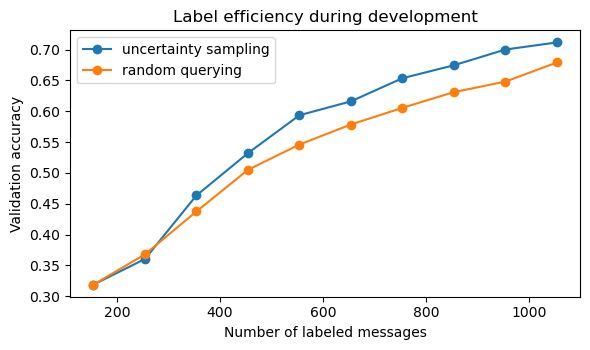

In [8]:
plt.figure(figsize=(6, 3.6))
plt.plot(label_counts, active_scores, marker="o", label="uncertainty sampling")
plt.plot(label_counts, random_scores, marker="o", label="random querying")
plt.xlabel("Number of labeled messages")
plt.ylabel("Validation accuracy")
plt.title("Label efficiency during development")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "label_efficiency_during_development.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 9 — Open the test set once for each policy

Refit each policy's final labeled set and score both on the official test messages, once.

**Read the code.**

- Each policy gets one final model, trained on all the labels it bought, and one score on the official test messages.
- The second `print` pads its text with spaces so that the two numbers line up.

In [9]:
# One final model per policy, on all the labels it bought, scored once on the official test messages.
active_final = make_model().fit(X_pool[active_set], y_pool[active_set])
random_final = make_model().fit(X_pool[random_set], y_pool[random_set])
print(f"final test accuracy with {len(active_set)} labels, uncertainty sampling:",
      round(accuracy_score(y_msg_test, active_final.predict(X_msg_test)), 3))
print(f"final test accuracy with {len(random_set)} labels, random querying:    ",
      round(accuracy_score(y_msg_test, random_final.predict(X_msg_test)), 3))

final test accuracy with 1054 labels, uncertainty sampling: 0.725
final test accuracy with 1054 labels, random querying:     0.682


**What the output shows.** With 1,000 labels the baseline scores 0.638 on validation, against a ceiling of 0.882 with all 8,003. Self-training adopts 486 pseudo-labels, 98.8% of them right, and still scores slightly worse, 0.632. With 77 intents and 13 labels each, the model is confident only about the messages it already gets right, so its pseudo-labels add almost nothing new, and they tilt it towards the intents it already knows. Active learning works: the two policies are level for two rounds, then uncertainty sampling pulls ahead and stays there, 0.712 against 0.679 with 1,054 labels. On the test file the gap holds: 0.725 against 0.682, about 4 points from the same number of labels. Only the labels-only baseline shows which method helped.

**Checkpoint: before you move on**

- Labels only: 0.638. Self-training: 0.632. Every label: 0.882.
- With 1,054 labels, uncertainty sampling scores 0.725 on the test messages and random querying 0.682.

## Evidence

Write the numbers above to the results folder. These files are regenerated on every run; do not edit them by hand.

### Question 10 — Save the evidence

**Read the code.**

- Each dictionary in the list is one row of the metrics table. A key that a row lacks becomes a blank in that row.
- `ranked.head(review_budget).to_csv(...)` saves the review list itself, which is what Part A hands over.

In [10]:
metrics = pd.DataFrame([
    {"part": "A", "dataset": "creditcard_fraud_ulb", "model": "isolation_forest",
     "prevalence": prevalence, "roc_auc": roc_auc_score(y_test, anomaly_score),
     "average_precision": ap, f"frauds_in_top_{review_budget}": found},
    {"part": "B", "dataset": "banking77", "model": "labels only (1,000)",
     "validation_accuracy": accuracy_score(y_val, labels_only.predict(X_val))},
    {"part": "B", "dataset": "banking77", "model": "self_training (1,000 labels)",
     "validation_accuracy": accuracy_score(y_val, semi.predict(X_val))},
    {"part": "B", "dataset": "banking77", "model": "active (uncertainty)",
     "test_accuracy": accuracy_score(y_msg_test, active_final.predict(X_msg_test))},
    {"part": "B", "dataset": "banking77", "model": "active (random)",
     "test_accuracy": accuracy_score(y_msg_test, random_final.predict(X_msg_test))},
])
metrics.round(4).to_csv(RESULTS / "metrics.csv", index=False)
ranked.head(review_budget).to_csv(RESULTS / "top_ranked_transactions.csv", index=False)
curve = pd.DataFrame({"labels": label_counts,
                      "uncertainty_sampling": active_scores, "random_querying": random_scores})
curve.round(4).to_csv(RESULTS / "active_learning_curve.csv", index=False)
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

Saved: ['active_learning_curve.csv', 'label_efficiency_during_development.png', 'metrics.csv', 'precision_falls_as_the_review_budget_grows.png', 'top_ranked_transactions.csv']


## Try it yourself

A fraud team can review a fixed number of alerts a day. Print the fraud rate and the frauds found in the top 50, 100, 300 and 1,000 alerts. Then look inside the active learner: print the four pool messages its final model is least sure about, with its top two intents and the true one.

Attempt it in the cell below before reading the solution.

### Question 11 — Try it yourself

In [11]:
# Your work here

### One solution

### Question 12 — One solution

**Read the code.**

- The loop reuses `hits` from Question 4: `hits[:budget].mean()` is the fraud rate among the first `budget` alerts, and the sum is the number of frauds found.
- `np.argsort(probs, axis=1)[:, -2:]` gives, for each message, the columns of its two highest probabilities, and `active_final.classes_[...]` turns the column positions into labels.
- `np.argsort(margin)[:4]` picks the four messages the final model is least sure of.
- `intents[...]` turns a label number into its name, and `text[:75]` prints the first 75 characters of a message.

In [12]:
# Part 1: what each review budget finds, from the ranked list of Question 3.
for budget in [50, 100, 300, 1000]:
    print(f"top {budget:4d} reviewed: fraud rate = {hits[:budget].mean():.1%}  "
          f"({int(hits[:budget].sum())} frauds found)")

# Part 2: what did the active learner ask about? The messages its final model is least sure of.
unlabeled = np.setdiff1d(np.arange(len(y_pool)), active_set)
probs = active_final.predict_proba(X_pool[unlabeled])
top_two = active_final.classes_[np.argsort(probs, axis=1)[:, -2:]]      # its two most likely intents
sorted_probs = np.sort(probs, axis=1)
margin = sorted_probs[:, -1] - sorted_probs[:, -2]
for i in np.argsort(margin)[:4]:
    text = pool["text"].iloc[unlabeled[i]]
    first, second, truth = intents[top_two[i, 1]], intents[top_two[i, 0]], intents[y_pool[unlabeled[i]]]
    print(f"{text[:75]}")
    print(f"    {first} or {second}?  truly {truth}")

top   50 reviewed: fraud rate = 50.0%  (25 frauds found)
top  100 reviewed: fraud rate = 39.0%  (39 frauds found)
top  300 reviewed: fraud rate = 21.0%  (63 frauds found)
top 1000 reviewed: fraud rate = 9.9%  (99 frauds found)
Hello, I have noticed a problem on my recent withdrawal at the banks atm ma
    cash_withdrawal_charge or pending_cash_withdrawal?  truly cash_withdrawal_charge
I had a problem with my card payment, can you help?
    declined_card_payment or reverted_card_payment??  truly declined_card_payment
I was wondering why my payment hasn't gone through yet, its been a while.
    transfer_not_received_by_recipient or pending_card_payment?  truly pending_card_payment
My identity can't be verified.
    why_verify_identity or unable_to_verify_identity?  truly unable_to_verify_identity


**What it shows.** The fraud rate falls from 50.0% in the top 50 alerts to 39.0% in the top 100, 21.0% in the top 300 and 9.9% in the top 1,000, which still finds 99 of the 148 frauds. The messages the active learner would buy next are genuinely ambiguous: a payment that "hasn't gone through yet" could be a pending card payment or a transfer the recipient has not received, and "My identity can't be verified" sits between two identity intents. Those are exactly the cases where a human label teaches the model the most.